# NVDA Stock Direction Classification

This notebook follows the GeeksforGeeks stock prediction workflow using daily NVDA data from Yahoo Finance. The task is binary classification: predict whether the next trading day's Close is higher than today's. It does not predict a price target or prove a profitable strategy.

Pipeline: download and inspect → EDA → feature engineering and target → chronological train/validation/test split → training-only preprocessing → compare Logistic Regression, polynomial SVC and XGBoost → evaluate.

Reference: [GeeksforGeeks tutorial](https://www.geeksforgeeks.org/machine-learning/stock-price-prediction-using-machine-learning-in-python/). Install if required: pip install yfinance seaborn scikit-learn xgboost.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yfinance as yf
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score,
    f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

## 1. Download and inspect data

Fetch ten years of daily NVDA OHLCV data. Yahoo Finance may return multi-level columns or an incomplete latest row, so normalize columns, sort dates, and remove rows missing essential market values.

In [3]:
TICKER = "NVDA"
raw = yf.download(TICKER, period="10y", interval="1d", auto_adjust=False,
                  progress=False, threads=False)
if raw.empty:
    raise ValueError("Yahoo Finance returned no rows; check the ticker or try again later.")
if isinstance(raw.columns, pd.MultiIndex):
    raw.columns = raw.columns.get_level_values(0)
df = raw.reset_index()
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
required = ["Date", "Open", "High", "Low", "Close", "Adj Close", "Volume"]
missing = set(required) - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")
df = (df[required].dropna(subset=["Date", "Open", "High", "Low", "Close", "Volume"])
      .sort_values("Date").drop_duplicates("Date").reset_index(drop=True))
print(f"{TICKER}: {len(df):,} rows, {df.Date.min().date()} to {df.Date.max().date()}")
display(df.head())
print("Shape:", df.shape)
display(df.describe().T)
df.info()

NVDA: 2,514 rows, 2016-11-07 to 2026-11-06
Shape: (2514, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2514 entries, 0 to 2513
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   Date       2514 non-null   datetime64[ns]
 1   Open       2514 non-null   float64       
 2   High       2514 non-null   float64       
 3   Low        2514 non-null   float64       
 4   Close      2514 non-null   float64       
 5   Adj Close  2514 non-null   float64       
 6   Volume     2514 non-null   int64         
dtypes: datetime64[ns](1), float64(5), int64(1)
memory usage: 137.6 KB


Price       Date     Open     High     Low    Close  Adj Close      Volume
0     2016-11-07  1.73875  1.79300  1.7375  1.78175   1.748456   487580000
1     2016-11-08  1.78850  1.79425  1.7625  1.77900   1.745757   429884000
2     2016-11-09  1.73075  1.77250  1.7180  1.74900   1.716318   456532000
3     2016-11-10  1.78725  1.78750  1.6690  1.69425   1.662591   869280000
4     2016-11-11  1.98775  2.21925  1.9625  2.19925   2.158154  2175344000

            count  ...               std
Price              ...                  
Date         2514  ...               NaN
Open       2514.0  ...         68.157318
High       2514.0  ...         69.091124
Low        2514.0  ...         67.045295
Close      2514.0  ...         68.044593
Adj Close  2514.0  ...         67.932671
Volume     2514.0  ...  265383175.405842

[7 rows x 8 columns]

## 2. Exploratory data analysis

Plot the close price, inspect missingness and compare raw Close with Adj Close. Adjusted prices account for corporate actions; the classifier uses raw OHLC, matching the reference tutorial.

Close equals Adj Close: 42 / 2514
Adjustment factor range: 0.98131 to 1.00000


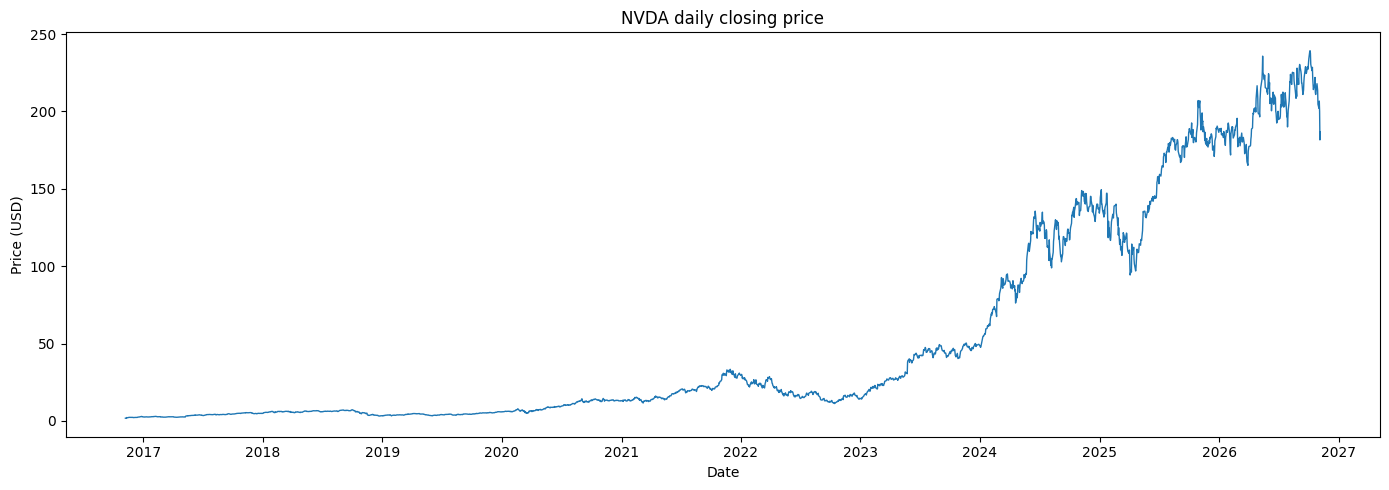

           missing
Price             
Date             0
Open             0
High             0
Low              0
Close            0
Adj Close        0
Volume           0

In [5]:
plt.figure(figsize=(14, 5))
plt.plot(df.Date, df.Close, linewidth=1)
plt.title(f"{TICKER} daily closing price")
plt.xlabel("Date"); plt.ylabel("Price (USD)")
plt.tight_layout(); plt.show()
display(df.isna().sum().to_frame("missing"))
print("Close equals Adj Close:", (df.Close == df["Adj Close"]).sum(), "/", len(df))
factor = df["Adj Close"] / df.Close
print(f"Adjustment factor range: {factor.min():.5f} to {factor.max():.5f}")

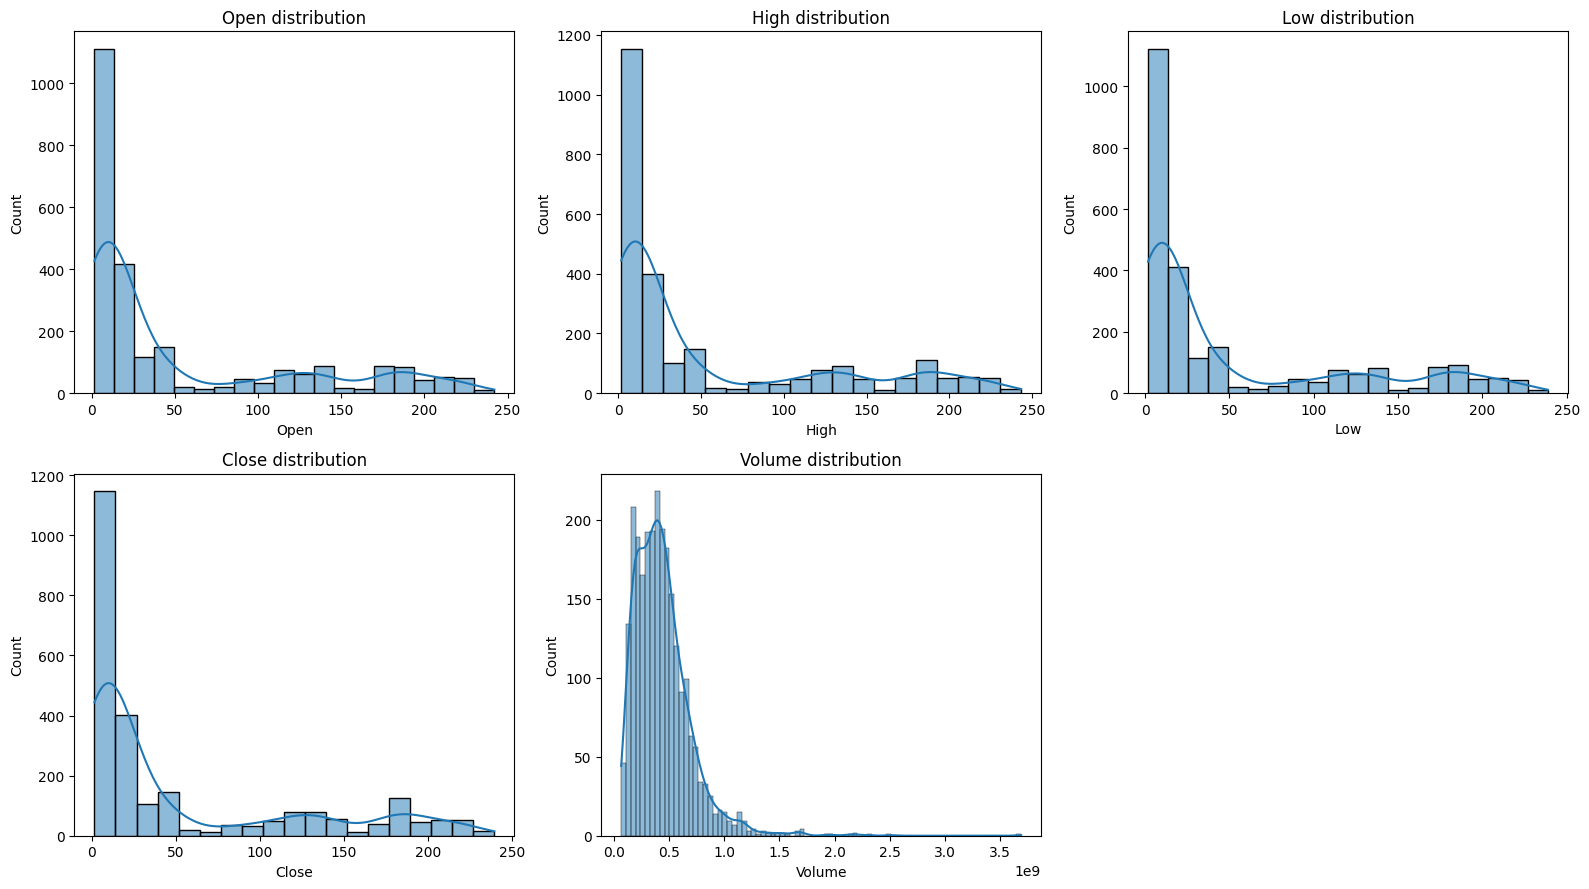

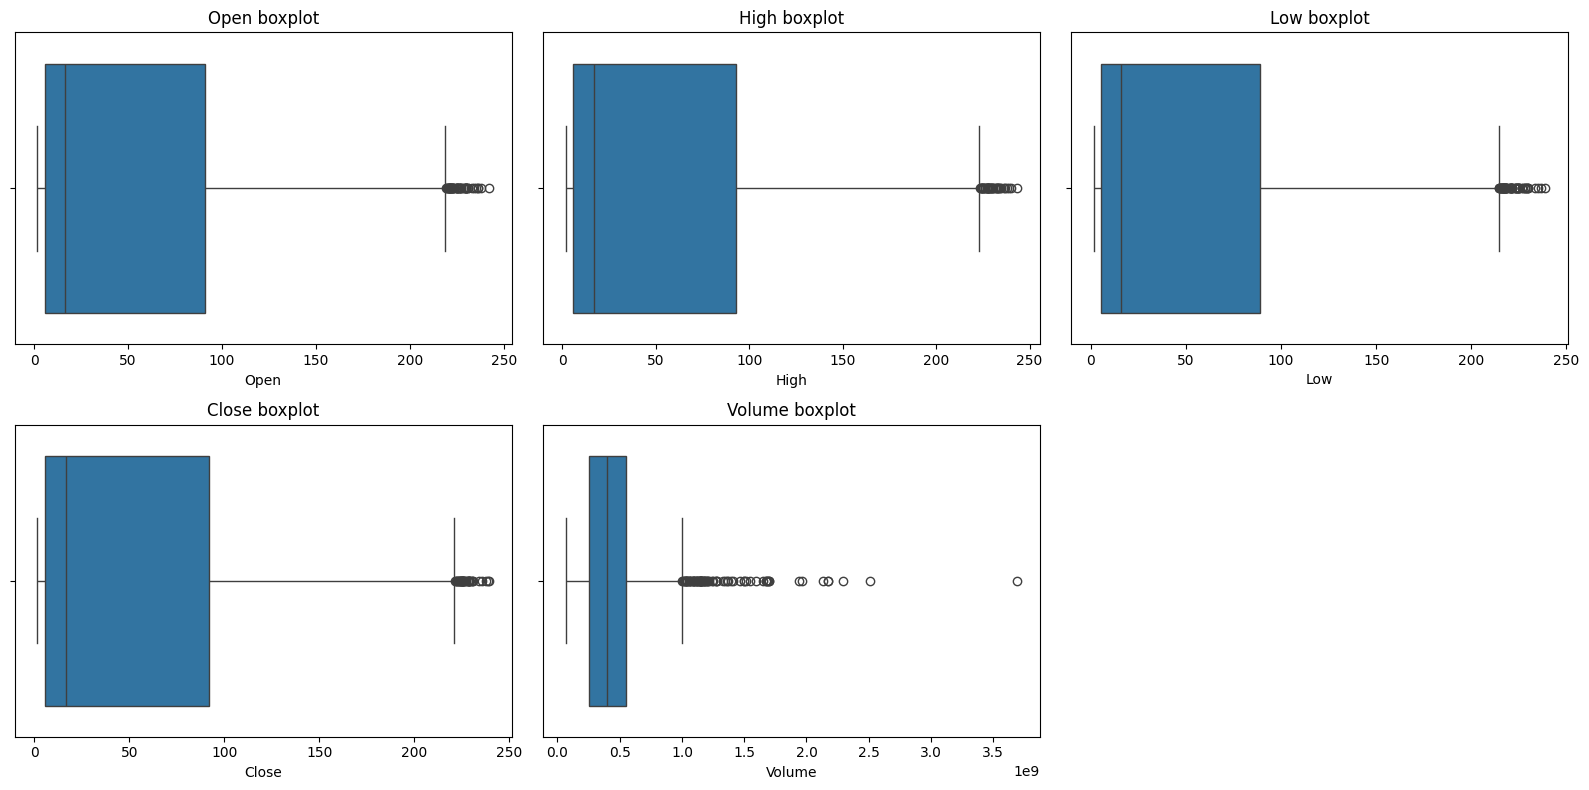

In [6]:
eda_cols = ["Open", "High", "Low", "Close", "Volume"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, eda_cols):
    sns.histplot(df[col], kde=True, ax=ax); ax.set_title(f"{col} distribution")
for ax in axes.flat[len(eda_cols):]: ax.remove()
plt.tight_layout(); plt.show()
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, eda_cols):
    sns.boxplot(x=df[col], ax=ax); ax.set_title(f"{col} boxplot")
for ax in axes.flat[len(eda_cols):]: ax.remove()
plt.tight_layout(); plt.show()

## 3. Feature engineering and target

Create calendar features and the tutorial's open-close and low-high features. The last row has no next-day close, so its target is missing and removed instead of being incorrectly labeled 0.

Target proportion (1 = next trading day closes higher):


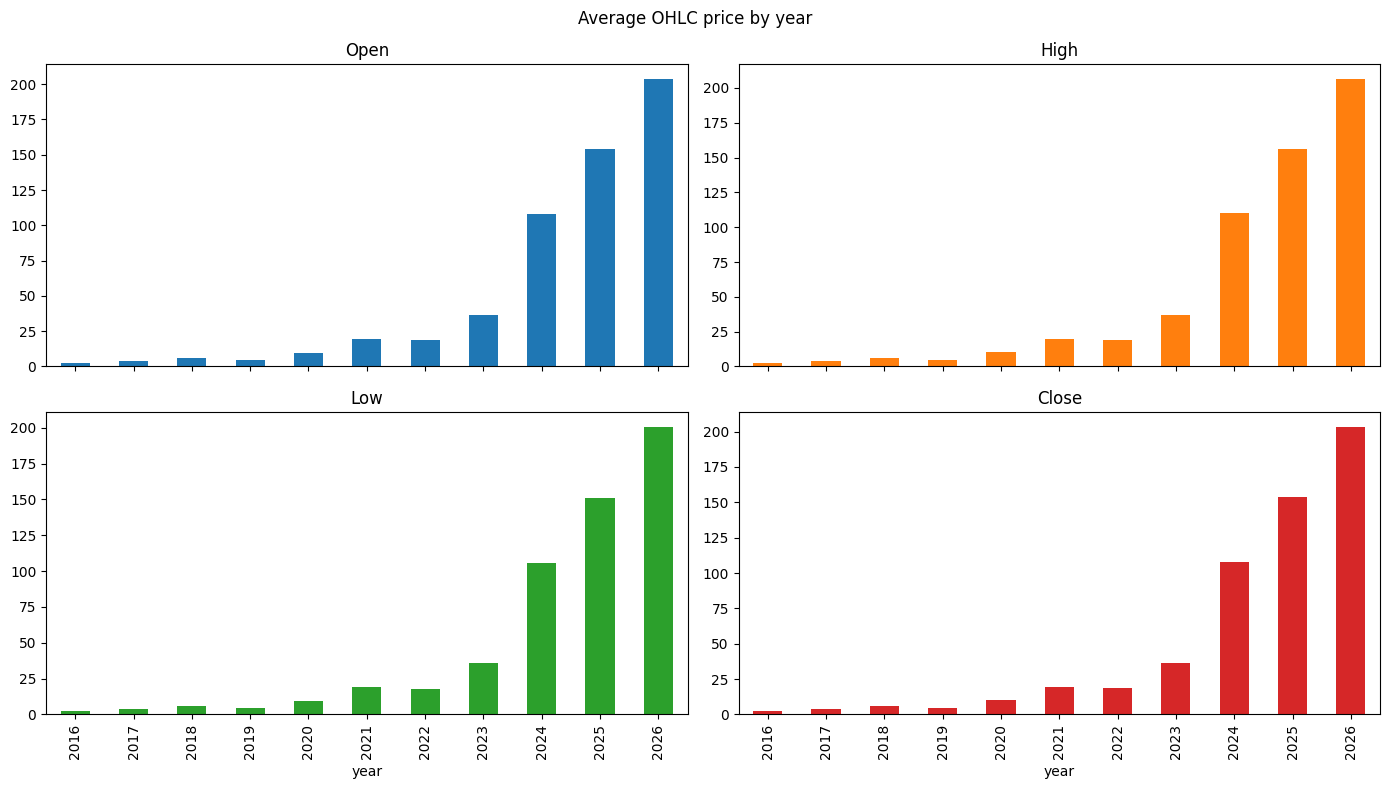

Price               Close        Volume
is_quarter_end                         
0               53.751930  4.353318e+08
1               52.394597  4.459476e+08

              proportion
target                  
0: flat/down    0.461202
1: up           0.538798

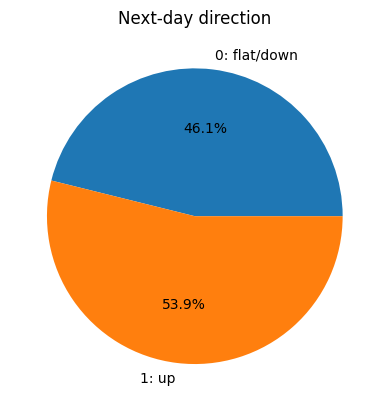

In [8]:
work = df.copy()
work["day"] = work.Date.dt.day
work["month"] = work.Date.dt.month
work["year"] = work.Date.dt.year
work["is_quarter_end"] = work.month.mod(3).eq(0).astype(int)

yearly = work.groupby("year")[["Open", "High", "Low", "Close"]].mean()
yearly.plot(kind="bar", subplots=True, layout=(2, 2), figsize=(14, 8),
            legend=False, sharex=True)
plt.suptitle("Average OHLC price by year"); plt.tight_layout(); plt.show()
display(work.groupby("is_quarter_end")[["Close", "Volume"]].mean())

work["open-close"] = work.Open - work.Close
work["low-high"] = work.Low - work.High
next_close = work.Close.shift(-1)
work["target"] = np.where(next_close.notna(), (next_close > work.Close).astype(int), np.nan)
work = work.dropna(subset=["target"]).reset_index(drop=True)
work["target"] = work.target.astype(int)

print("Target proportion (1 = next trading day closes higher):")
display(work.target.value_counts(normalize=True).sort_index().rename(
    index={0:"0: flat/down", 1:"1: up"}).to_frame("proportion"))
work.target.value_counts().sort_index().rename(index={0:"0: flat/down", 1:"1: up"}).plot(
    kind="pie", autopct="%1.1f%%", ylabel="", title="Next-day direction")
plt.show()

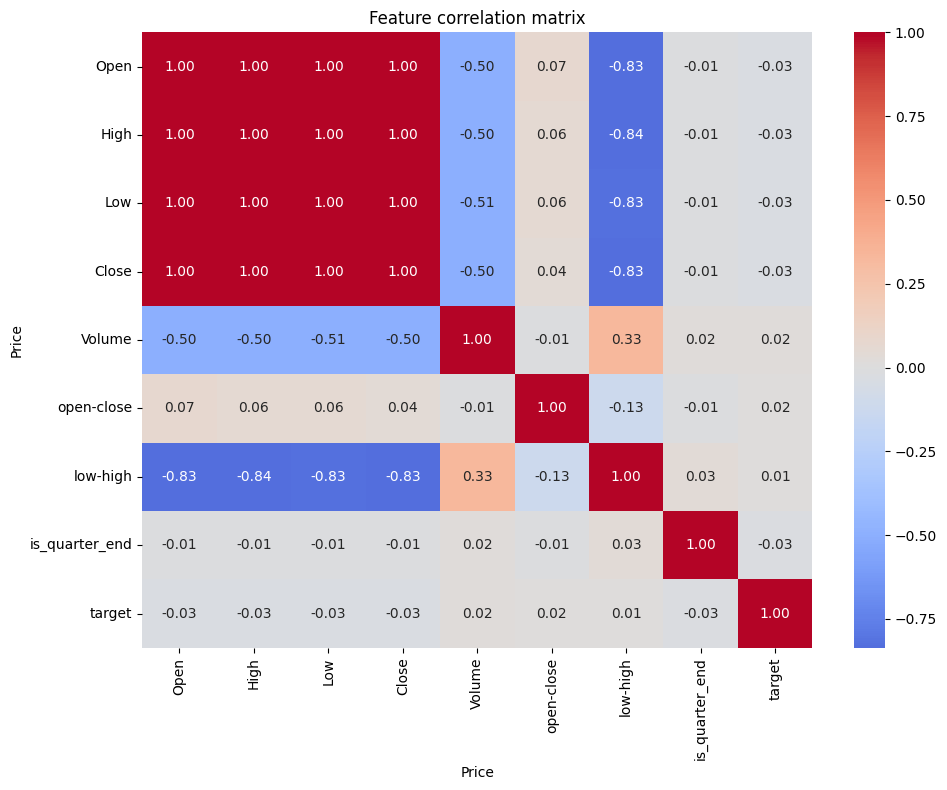

In [9]:
corr_cols = ["Open", "High", "Low", "Close", "Volume", "open-close",
             "low-high", "is_quarter_end", "target"]
plt.figure(figsize=(10, 8))
sns.heatmap(work[corr_cols].corr(numeric_only=True), cmap="coolwarm",
            center=0, annot=True, fmt=".2f")
plt.title("Feature correlation matrix"); plt.tight_layout(); plt.show()

## 4. Chronological split and preprocessing

Use the oldest 80% for training, the next 10% for model selection, and the latest 10% for final testing. Each model pipeline learns imputation and scaling from its training portion only. The final test remains unseen until after model selection.

In [11]:
FEATURES = ["open-close", "low-high", "is_quarter_end"]
cut_train, cut_dev = int(len(work) * 0.8), int(len(work) * 0.9)
train = work.iloc[:cut_train].copy()
valid = work.iloc[cut_train:cut_dev].copy()
test = work.iloc[cut_dev:].copy()
X_train, y_train = train[FEATURES], train.target
X_valid, y_valid = valid[FEATURES], valid.target
X_test, y_test = test[FEATURES], test.target
for name, part in [("Train",train),("Validation",valid),("Test",test)]:
    print(f"{name}: {len(part)} rows, {part.Date.min().date()} to {part.Date.max().date()}")
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
print(f"Validation majority-class accuracy: {accuracy_score(y_valid, baseline.predict(X_valid)):.3f}")

Train: 2010 rows, 2016-11-07 to 2024-11-01
Validation: 251 rows, 2024-11-04 to 2025-11-04
Test: 252 rows, 2025-11-05 to 2026-11-05
Validation majority-class accuracy: 0.534


## 5. Model development and evaluation

Compare Logistic Regression, polynomial SVC and XGBoost on the validation period, using ROC-AUC to choose a model. ROC-AUC measures how predicted probabilities rank the classes; it is not accuracy. The test period is evaluated after selection.

In [13]:
models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42)),
    ]),
    "Polynomial SVC": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="poly", probability=True, class_weight="balanced", random_state=42)),
    ]),
    "XGBoost": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03,
            subsample=0.8, colsample_bytree=0.8, reg_lambda=1.0,
            eval_metric="logloss", random_state=42, n_jobs=-1)),
    ]),
}

def score_model(model, X_fit, y_fit, X_eval, y_eval):
    model.fit(X_fit, y_fit)
    p_fit = model.predict_proba(X_fit)[:, 1]
    p_eval = model.predict_proba(X_eval)[:, 1]
    pred = (p_eval >= 0.5).astype(int)
    return {
        "train_roc_auc": roc_auc_score(y_fit, p_fit),
        "validation_roc_auc": roc_auc_score(y_eval, p_eval),
        "validation_accuracy": accuracy_score(y_eval, pred),
        "validation_balanced_accuracy": balanced_accuracy_score(y_eval, pred),
        "validation_precision": precision_score(y_eval, pred, zero_division=0),
        "validation_recall": recall_score(y_eval, pred, zero_division=0),
        "validation_f1": f1_score(y_eval, pred, zero_division=0),
    }

results = {name: score_model(model, X_train, y_train, X_valid, y_valid)
           for name, model in models.items()}
results_df = pd.DataFrame(results).T.sort_values("validation_roc_auc", ascending=False)
display(results_df.round(3))
best_name = results_df.index[0]
print("Selected by validation ROC-AUC:", best_name)

from sklearn.base import clone
development = work.iloc[:cut_dev]
X_dev, y_dev = development[FEATURES], development.target
best_model = clone(models[best_name]).fit(X_dev, y_dev)
test_prob = best_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= 0.5).astype(int)
test_results = pd.Series({
    "test_roc_auc": roc_auc_score(y_test, test_prob),
    "test_accuracy": accuracy_score(y_test, test_pred),
    "test_balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "test_precision": precision_score(y_test, test_pred, zero_division=0),
    "test_recall": recall_score(y_test, test_pred, zero_division=0),
    "test_f1": f1_score(y_test, test_pred, zero_division=0),
    "test_majority_baseline_accuracy": accuracy_score(
        y_test, DummyClassifier(strategy="most_frequent").fit(X_dev, y_dev).predict(X_test)),
})
display(test_results.round(3).to_frame("score"))

Selected by validation ROC-AUC: Polynomial SVC


                     train_roc_auc  ...  validation_f1
Polynomial SVC               0.478  ...          0.695
Logistic Regression          0.521  ...          0.531
XGBoost                      0.719  ...          0.621

[3 rows x 7 columns]

                                 score
test_roc_auc                     0.508
test_accuracy                    0.500
test_balanced_accuracy           0.500
test_precision                   0.500
test_recall                      1.000
test_f1                          0.667
test_majority_baseline_accuracy  0.500

## 6. Test confusion matrix and conclusion

The confusion matrix uses the same 0.5 probability threshold as the metrics above. A ROC-AUC near 0.5 or accuracy near the majority baseline gives little evidence that these features can predict next-day direction.

Final test: 2025-11-05 to 2026-11-05
This classification experiment omits execution timing, transaction costs and risk management.


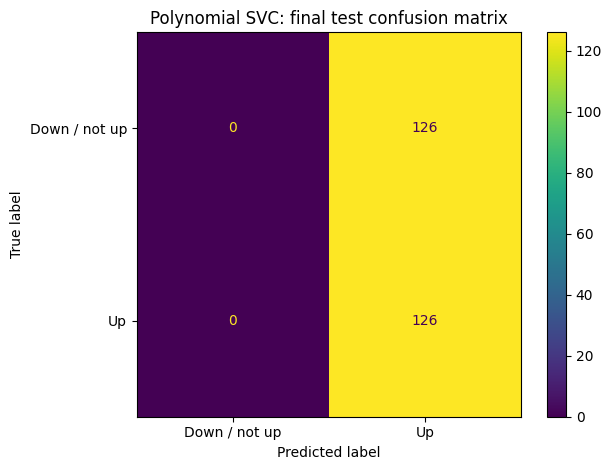

In [15]:
ConfusionMatrixDisplay.from_predictions(
    y_test, test_pred, display_labels=["Down / not up", "Up"])
plt.title(f"{best_name}: final test confusion matrix")
plt.tight_layout(); plt.show()
print("Final test:", test.Date.min().date(), "to", test.Date.max().date())
print("This classification experiment omits execution timing, transaction costs and risk management.")

## Summary

This project follows the main GeeksforGeeks sequence with NVDA data and adds chronological train/validation/test evaluation, training-only preprocessing, a majority-class baseline, and more evaluation metrics. It predicts next-day direction, not price. Results should not be interpreted as investment returns.

Data source: Yahoo Finance through the yfinance package. Data availability and historical values can change.